In [1]:
# Nếu Kaggle thiếu package
!pip install -q polars seaborn pyarrow


# 1. Setup

In [2]:
import os
import polars as pl
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.05,
    rc={
        "figure.figsize": (12, 6),
        "axes.titlesize": 16,
        "axes.labelsize": 12,
        "axes.titleweight": "bold"
    }
)

BASE_PATH = "/kaggle/input/datasets/brdh7940/vietnamese-legal-documents-cleaned"

CONTENT_PATH = f"{BASE_PATH}/content.parquet"
META_PATH = f"{BASE_PATH}/metadata.parquet"
REL_PATH = f"{BASE_PATH}/relationships.parquet"

print(os.listdir(BASE_PATH))

['relationships.parquet', 'content.parquet', 'metadata.parquet']


# 2. Overview

In [3]:

import os
import polars as pl
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.05,
    rc={
        "figure.figsize": (12, 6),
        "axes.titlesize": 16,
        "axes.labelsize": 12,
        "axes.titleweight": "bold"
    }
)

BASE_PATH = "/kaggle/input/datasets/brdh7940/vietnamese-legal-documents-cleaned"

CONTENT_PATH = f"{BASE_PATH}/content.parquet"
META_PATH = f"{BASE_PATH}/metadata.parquet"
REL_PATH = f"{BASE_PATH}/relationships.parquet"

print(os.listdir(BASE_PATH))

['relationships.parquet', 'content.parquet', 'metadata.parquet']


# 3. Load Dataset

In [4]:
content = pl.read_parquet(CONTENT_PATH)
metadata = pl.read_parquet(META_PATH)
relationships = pl.read_parquet(REL_PATH)

print("content:", content.shape)
print("metadata:", metadata.shape)
print("relationships:", relationships.shape)

display(content.head().to_pandas())
display(metadata.head().to_pandas())
display(relationships.head().to_pandas())

content: (353746, 3)
metadata: (353746, 18)
relationships: (138656, 3)


,id,content,source
0,363905,ỦY BAN NHÂN DÂN TỈNH BẠC LIÊU | CỘNG HÒA XÃ HỘ...,legacy
1,493846,BỘ XÂY DỰNG | CỘNG HÒA XÃ HỘI CHỦ NGHĨA VIỆT N...,legacy
2,10000155222,NGHỊ QUYẾT\nBan hành quy định một số chế độ ch...,data
3,43126,QUYẾT ĐỊNH\n\nCỦA HỘI ĐỒNG BỘ TRƯỞNG SỐ 67/HĐB...,legacy+data
4,430876,ỦY BAN NHÂN DÂN TỈNH KON TUM | CỘNG HÒA XÃ HỘI...,legacy


,id,document_number,title,legal_type,legal_sectors,issuing_authority,issuance_date,effect_date,effectless_date,effect_status,signers,nguon_thu_thap,ngay_dang_cong_bao,nganh,linh_vuc,chuc_danh,pham_vi,source
0,693036,115/NQ-HĐBCQG,Nghị quyết 115/NQ-HĐBCQG năm 2026 hướng dẫn xử...,Nghị quyết,Bộ máy hành chính,Hội đồng bầu cử quốc gia,2026-01-29,2026-01-29,None,Còn hiệu lực,Trần Thanh Mẫn:2140,None,None,None,None,None,None,legacy
1,680604,34/2025/QĐ-UBND,Quy định khoảng cách và địa bàn làm căn cứ xác...,Quyết định,Giáo dục và đào tạo,Ủy ban nhân dân tỉnh Quảng Trị,2025-10-31,2025-11-09,None,Còn hiệu lực,Hoàng Xuân Tân,None,None,Giáo dục và đào tạo,None,Phó Chủ tịch,Tỉnh Quảng Trị,legacy+data
2,694312,06/2026/QĐ-UBND,"Quy định phân cấp quản lý, bảo vệ, thực hiện c...",Quyết định,"Bất động sản, Giao thông vận tải",UBND thành phố Hồ Chí Minh,2026-02-09,2026-02-20,None,Còn hiệu lực,Bùi Xuân Cường,Bản chính văn bản,None,None,None,Phó Chủ tịch,Thành phố Hồ Chí Minh,legacy+data
3,680585,38/2025/NQ-HĐND,"Chính sách, chế độ đối với người làm việc ngoà...",Nghị quyết,"Lao động - tiền lương, Bộ máy hành chính",HĐND tỉnh Lâm Đồng,2025-10-27,2025-10-27,None,Còn hiệu lực,K' Mák,văn bản gốc,None,None,None,Phó Chủ tịch,tỉnh lâm đồng,legacy+data
4,680581,134/2025/QĐ-CTUBND,"Phân cấp tổ chức thẩm định, phê duyệt dự toán ...",Quyết định,Đầu tư,Chủ tịch Ủy ban nhân dân tỉnh Đồng Tháp,2025-11-10,2025-11-20,None,Còn hiệu lực,Trần Trí Quang,None,None,None,None,Chủ tịch,tỉnh Đồng tháp,legacy+data


,doc_id,other_doc_id,relationship
0,470874,459854,Văn bản căn cứ
1,565142,466331,Văn bản căn cứ
2,604148,152715,Văn bản căn cứ
3,673893,335331,Văn bản căn cứ
4,674103,238644,Văn bản căn cứ


# 3. Missing value heatmap cho metadata

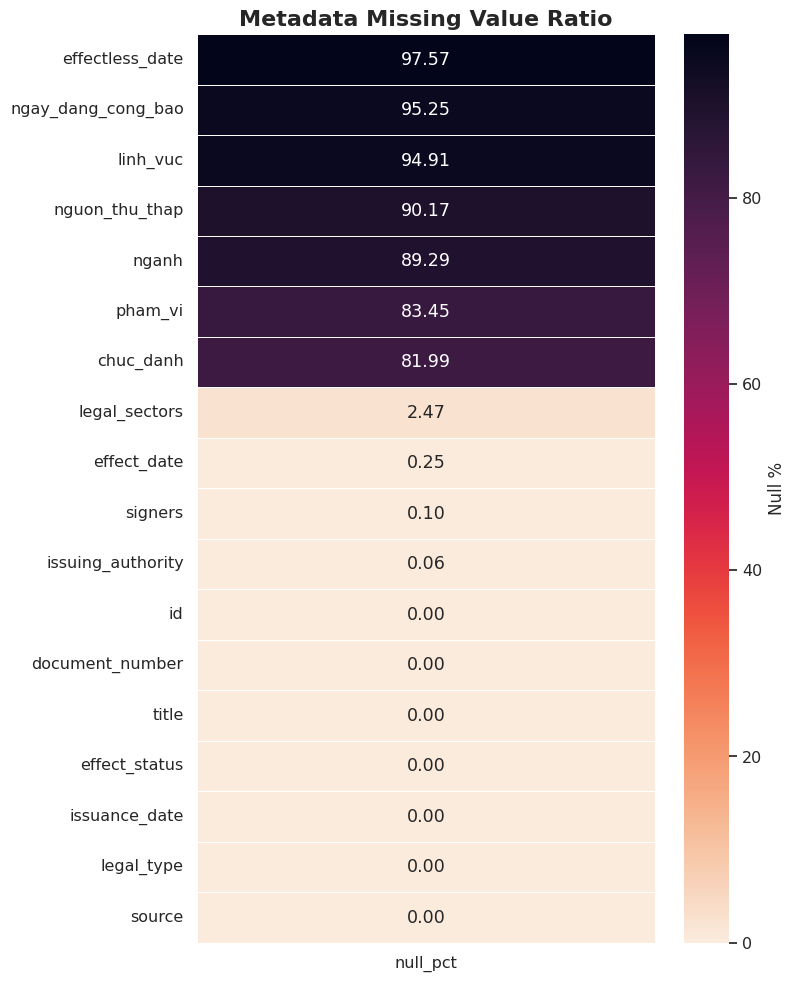

In [5]:
null_df = (
    metadata
    .select([
        (pl.col(c).is_null().mean() * 100).round(2).alias(c)
        for c in metadata.columns
    ])
    .to_pandas()
    .T
    .reset_index()
)

null_df.columns = ["column", "null_pct"]
null_df = null_df.sort_values("null_pct", ascending=False)

plt.figure(figsize=(8, 10))
sns.heatmap(
    null_df.set_index("column")[["null_pct"]],
    annot=True,
    fmt=".2f",
    cmap="rocket_r",
    linewidths=0.5,
    cbar_kws={"label": "Null %"}
)

plt.title("Metadata Missing Value Ratio")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

# 4. Source distribution: content vs metadata

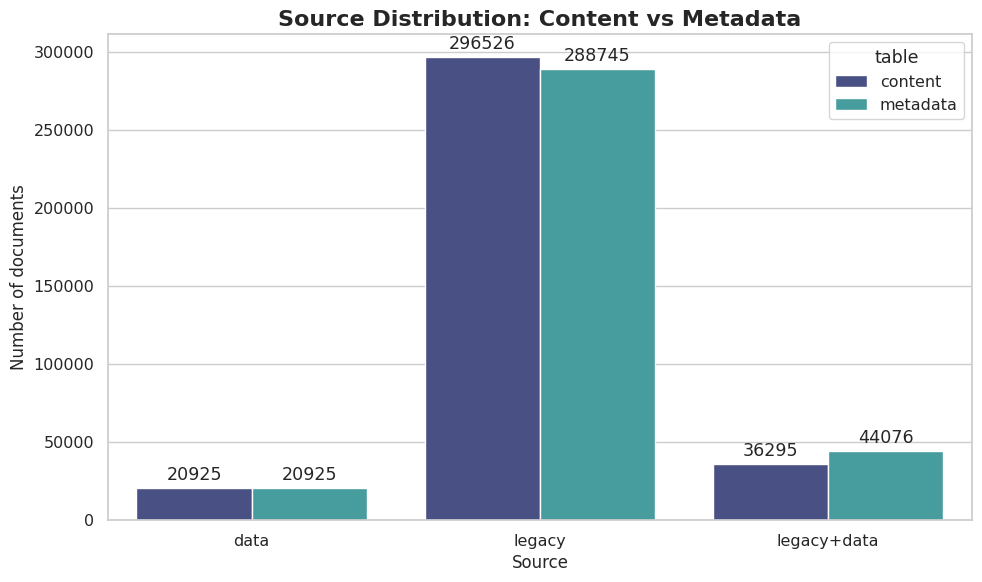

In [6]:
content_source = (
    content
    .group_by("source")
    .len()
    .with_columns((pl.col("len") / pl.col("len").sum() * 100).round(2).alias("pct"))
    .with_columns(pl.lit("content").alias("table"))
)

meta_source = (
    metadata
    .group_by("source")
    .len()
    .with_columns((pl.col("len") / pl.col("len").sum() * 100).round(2).alias("pct"))
    .with_columns(pl.lit("metadata").alias("table"))
)

source_df = pl.concat([content_source, meta_source]).to_pandas()

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=source_df,
    x="source",
    y="len",
    hue="table",
    palette="mako"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Source Distribution: Content vs Metadata")
plt.xlabel("Source")
plt.ylabel("Number of documents")
plt.tight_layout()
plt.show()

# 6. Content length buckets

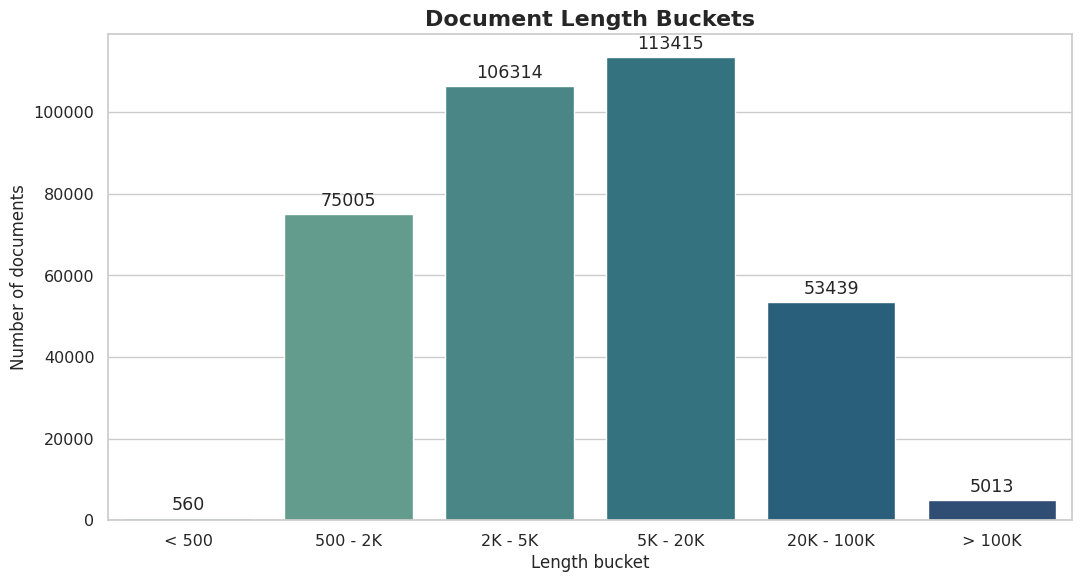

In [8]:
content_len = content.select(
    pl.col('content').str.len_chars().alias("content_len")
)

content_len_bucket = (
    content_len
    .with_columns(
        pl.when(pl.col("content_len") < 500).then(pl.lit("< 500"))
        .when(pl.col("content_len") < 2_000).then(pl.lit("500 - 2K"))
        .when(pl.col("content_len") < 5_000).then(pl.lit("2K - 5K"))
        .when(pl.col("content_len") < 20_000).then(pl.lit("5K - 20K"))
        .when(pl.col("content_len") < 100_000).then(pl.lit("20K - 100K"))
        .otherwise(pl.lit("> 100K"))
        .alias("length_bucket")
    )
    .group_by("length_bucket")
    .len()
)

bucket_order = ["< 500", "500 - 2K", "2K - 5K", "5K - 20K", "20K - 100K", "> 100K"]

bucket_pd = (
    content_len_bucket
    .to_pandas()
    .assign(length_bucket=lambda d: pd.Categorical(d["length_bucket"], categories=bucket_order, ordered=True))
    .sort_values("length_bucket")
)

plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=bucket_pd,
    x="length_bucket",
    y="len",
    hue="length_bucket",
    palette="crest",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Document Length Buckets")
plt.xlabel("Length bucket")
plt.ylabel("Number of documents")
plt.tight_layout()
plt.show()

# 7. Top legal types

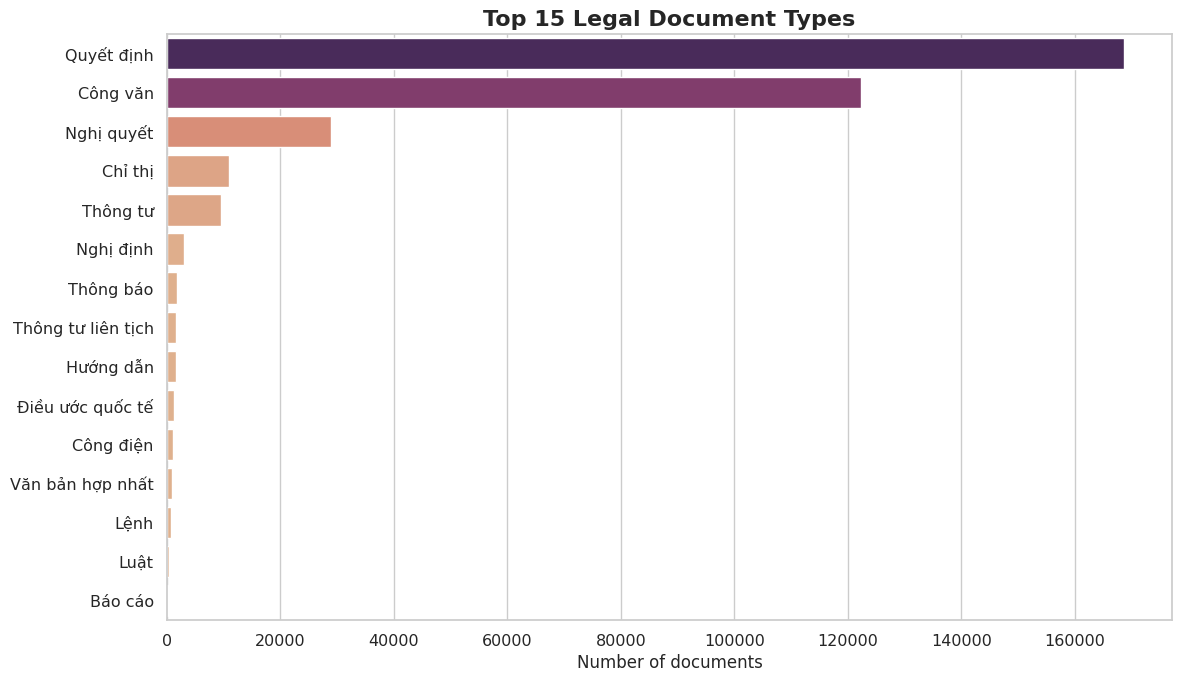

In [9]:
top_legal_type = (
    metadata
    .group_by("legal_type")
    .len()
    .sort("len", descending=True)
    .head(15)
    .to_pandas()
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_legal_type,
    y="legal_type",
    x="len",
    hue="len",
    palette="flare",
    legend=False
)

plt.title("Top 15 Legal Document Types")
plt.xlabel("Number of documents")
plt.ylabel("")
plt.tight_layout()
plt.show()

# 8. Số văn bản theo năm ban hành

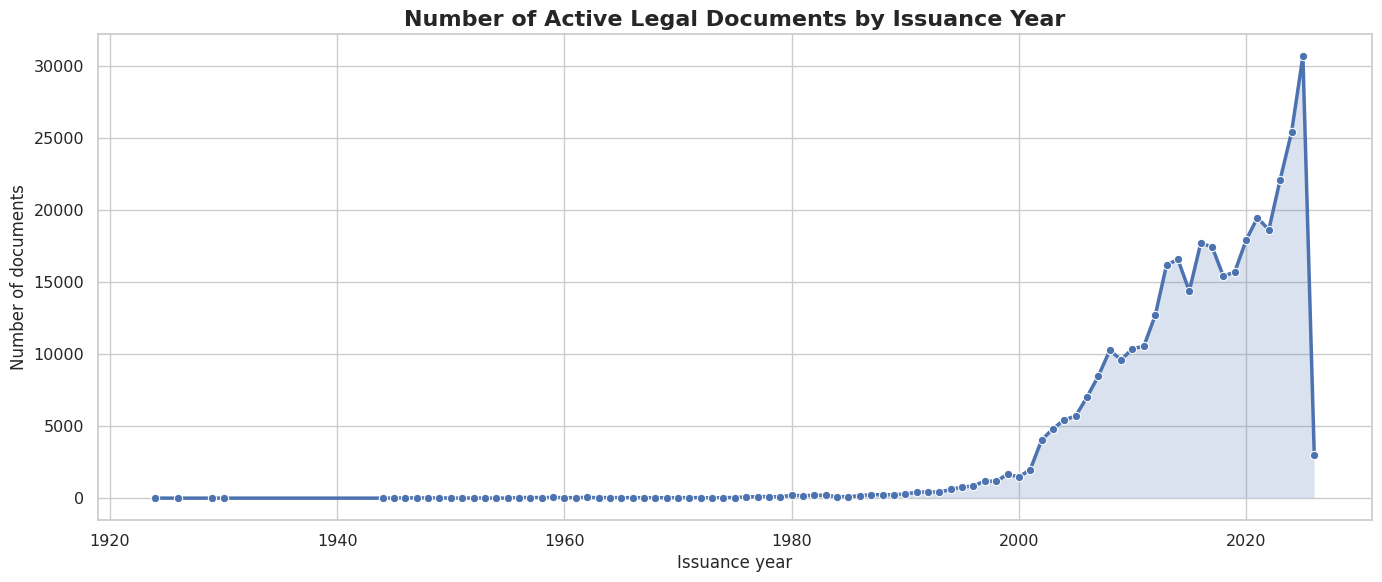

In [10]:
year_df = (
    metadata
    .with_columns(
        pl.col("issuance_date")
        .str.strptime(pl.Date, "%Y-%m-%d", strict=False)
        .dt.year()
        .alias("year")
    )
    .drop_nulls("year")
    .group_by("year")
    .len()
    .sort("year")
    .to_pandas()
)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=year_df,
    x="year",
    y="len",
    marker="o",
    linewidth=2.5
)

plt.fill_between(year_df["year"], year_df["len"], alpha=0.2)
plt.title("Number of Active Legal Documents by Issuance Year")
plt.xlabel("Issuance year")
plt.ylabel("Number of documents")
plt.tight_layout()
plt.show()

# 9. Heatmap: legal type theo năm gần đây

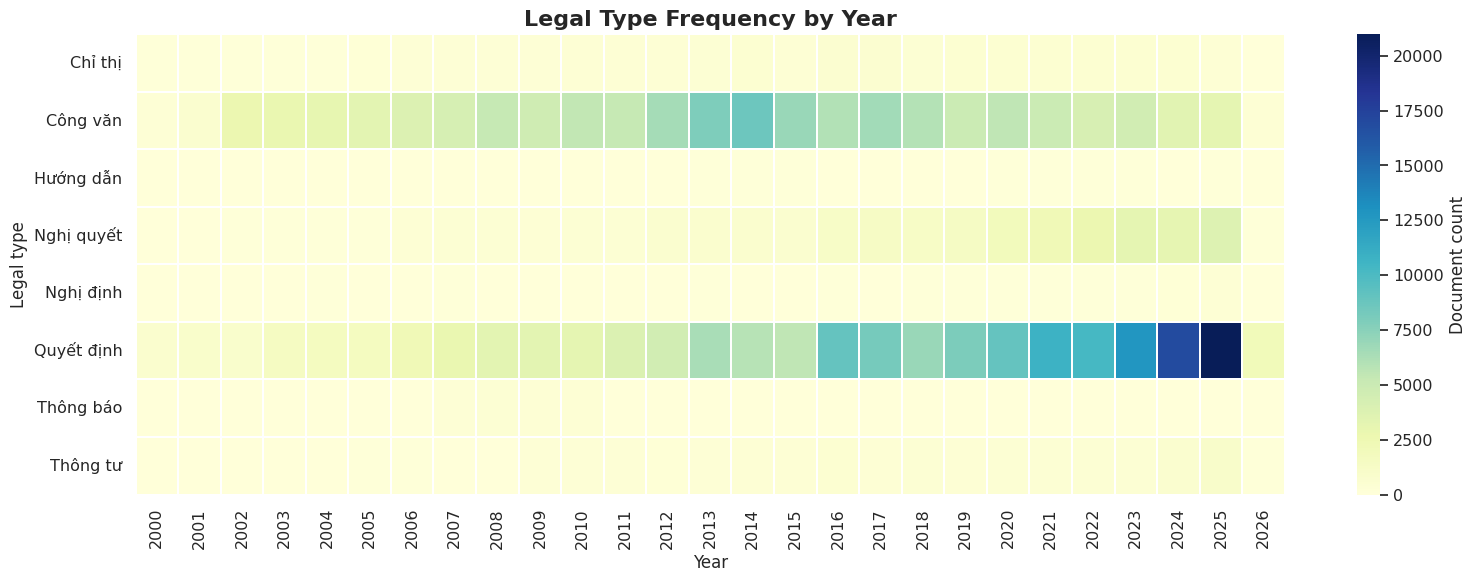

In [11]:
meta_year_type = (
    metadata
    .with_columns(
        pl.col("issuance_date")
        .str.strptime(pl.Date, "%Y-%m-%d", strict=False)
        .dt.year()
        .alias("year")
    )
    .drop_nulls(["year", "legal_type"])
    .filter(pl.col("year") >= 2000)
)

top_types = (
    meta_year_type
    .group_by("legal_type")
    .len()
    .sort("len", descending=True)
    .head(8)
    .select("legal_type")
    .to_series()
    .to_list()
)

heatmap_df = (
    meta_year_type
    .filter(pl.col("legal_type").is_in(top_types))
    .group_by(["year", "legal_type"])
    .len()
    .to_pandas()
    .pivot(index="legal_type", columns="year", values="len")
    .fillna(0)
)

plt.figure(figsize=(16, 6))
sns.heatmap(
    heatmap_df,
    cmap="YlGnBu",
    linewidths=0.2,
    cbar_kws={"label": "Document count"}
)

plt.title("Legal Type Frequency by Year")
plt.xlabel("Year")
plt.ylabel("Legal type")
plt.tight_layout()
plt.show()

# 10. Top issuing authorities

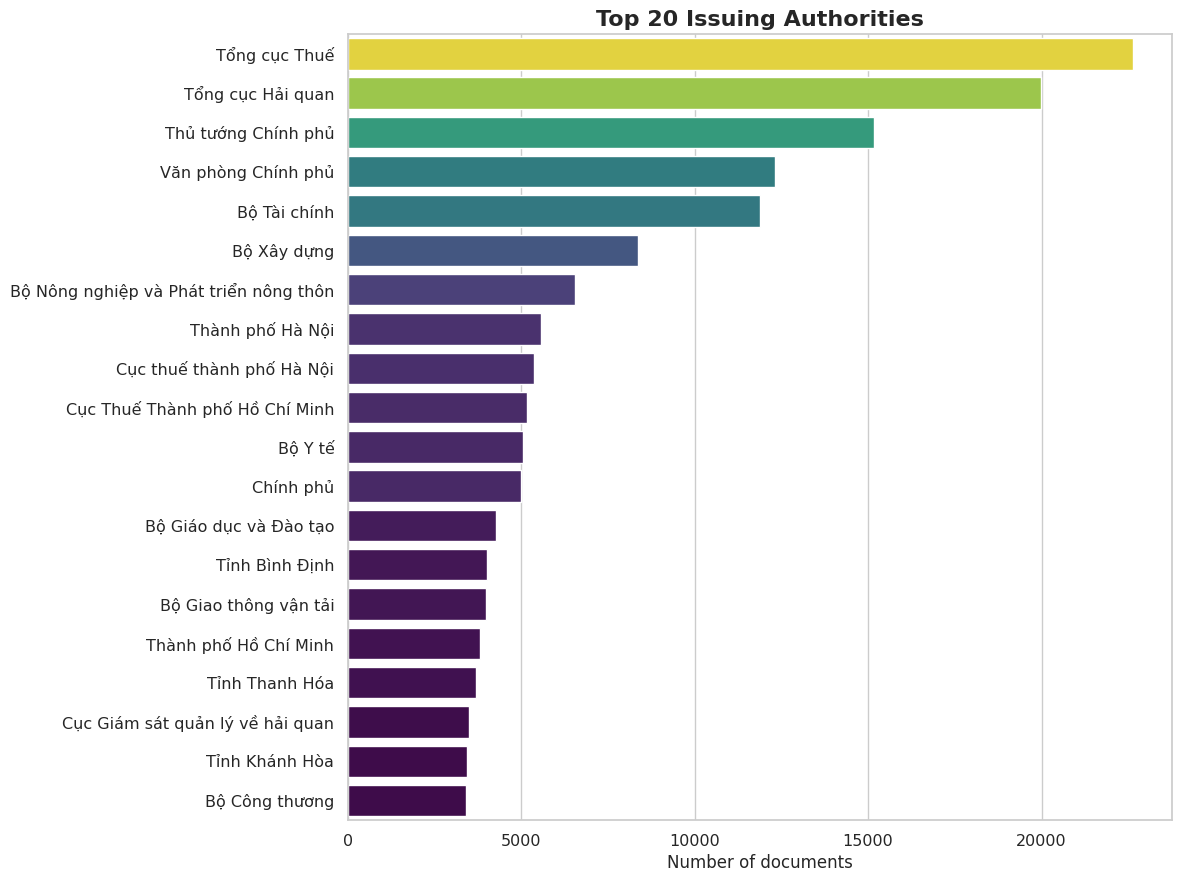

In [12]:
top_authority = (
    metadata
    .drop_nulls("issuing_authority")
    .group_by("issuing_authority")
    .len()
    .sort("len", descending=True)
    .head(20)
    .to_pandas()
)

plt.figure(figsize=(12, 9))
sns.barplot(
    data=top_authority,
    y="issuing_authority",
    x="len",
    hue="len",
    palette="viridis",
    legend=False
)

plt.title("Top 20 Issuing Authorities")
plt.xlabel("Number of documents")
plt.ylabel("")
plt.tight_layout()
plt.show()

# 11. Top legal sectors sau khi split multi-tag

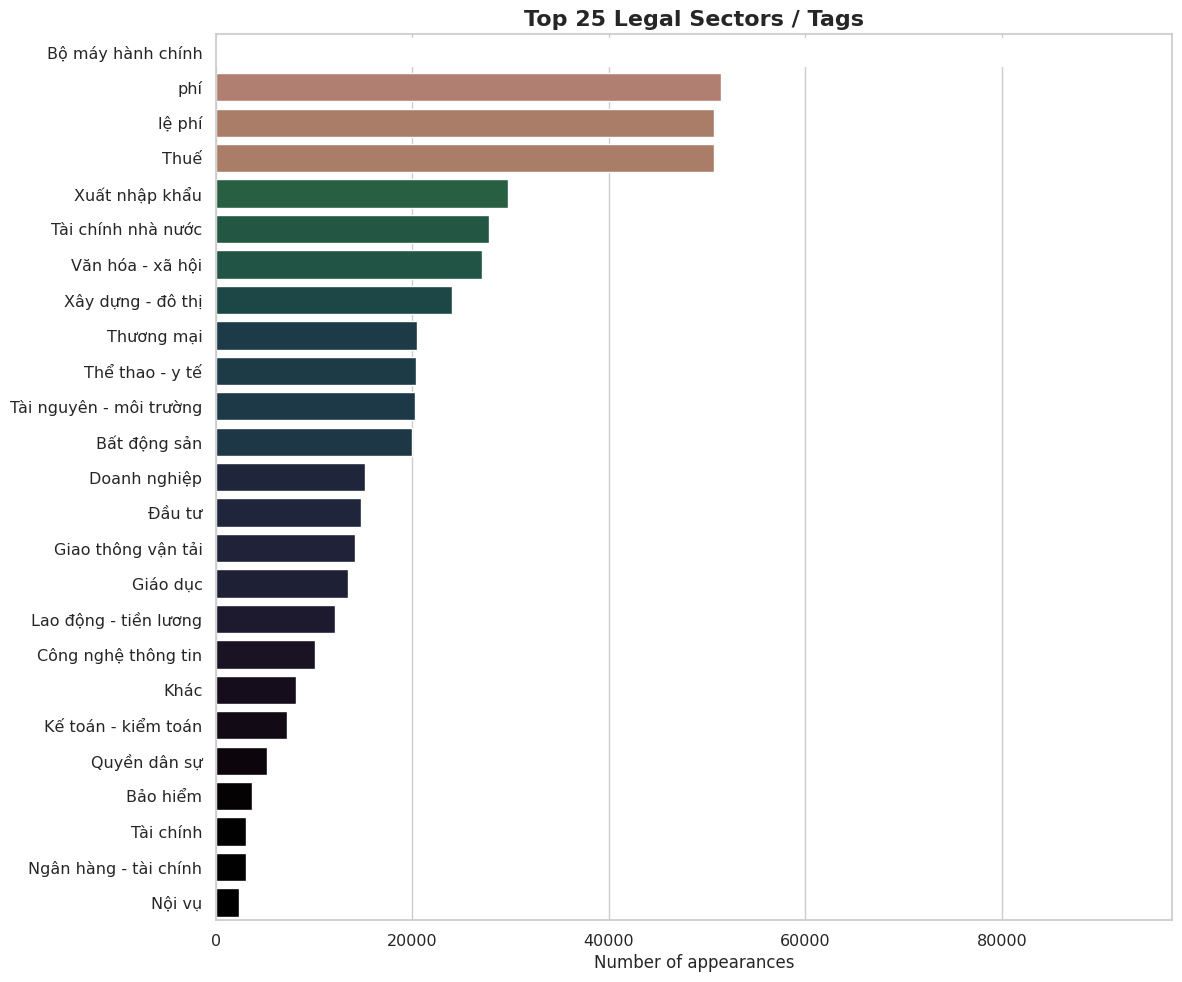

In [13]:
sector_df = (
    metadata
    .select(["id", "legal_sectors"])
    .drop_nulls("legal_sectors")
    .with_columns(
        pl.col("legal_sectors").str.split(", ").alias("sector")
    )
    .explode("sector")
    .with_columns(pl.col("sector").str.strip_chars())
    .filter(pl.col("sector") != "")
    .group_by("sector")
    .len()
    .sort("len", descending=True)
    .head(25)
    .to_pandas()
)

plt.figure(figsize=(12, 10))
sns.barplot(
    data=sector_df,
    y="sector",
    x="len",
    hue="len",
    palette="cubehelix",
    legend=False
)

plt.title("Top 25 Legal Sectors / Tags")
plt.xlabel("Number of appearances")
plt.ylabel("")
plt.tight_layout()
plt.show()

# 12. Relationship type distribution

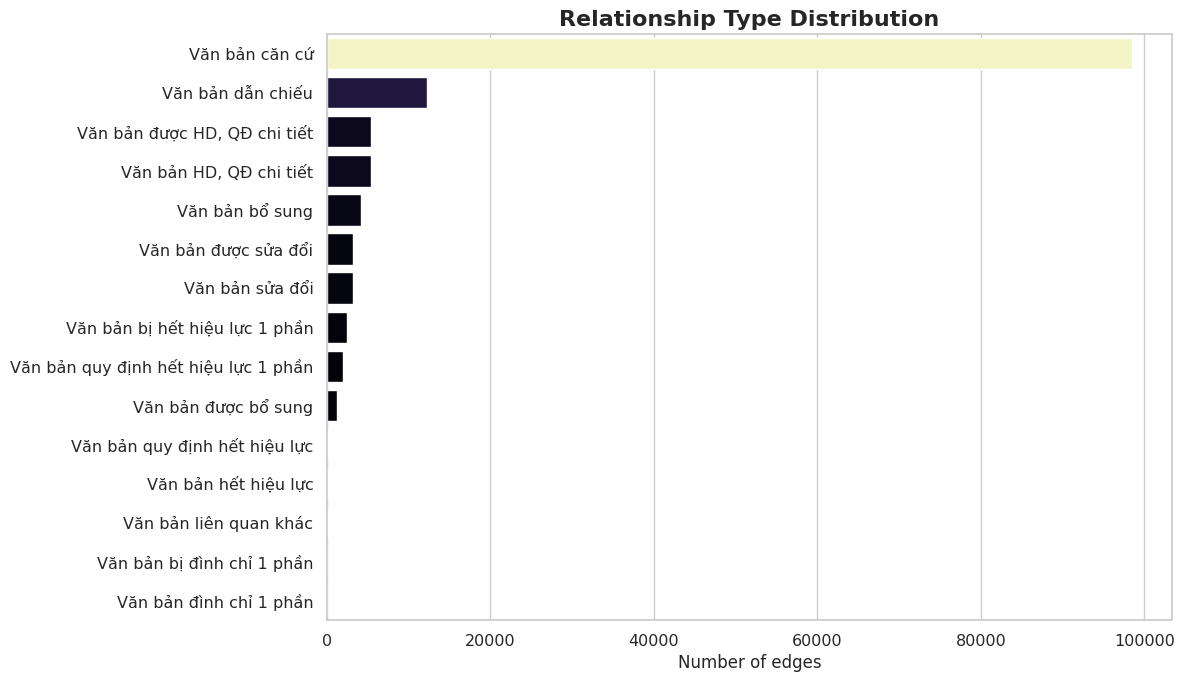

In [14]:
rel_type_df = (
    relationships
    .group_by("relationship")
    .len()
    .sort("len", descending=True)
    .to_pandas()
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=rel_type_df,
    y="relationship",
    x="len",
    hue="len",
    palette="magma",
    legend=False
)

plt.title("Relationship Type Distribution")
plt.xlabel("Number of edges")
plt.ylabel("")
plt.tight_layout()
plt.show()

# 13. Out-degree distribution

Giải thích:
- Node = văn bản pháp luật (doc_id)
- Edge = quan hệ tới văn bản khác (other_doc_id)
- Out-degree của một văn bản = số lượng văn bản khác mà nó tham chiếu/liên kết tới.

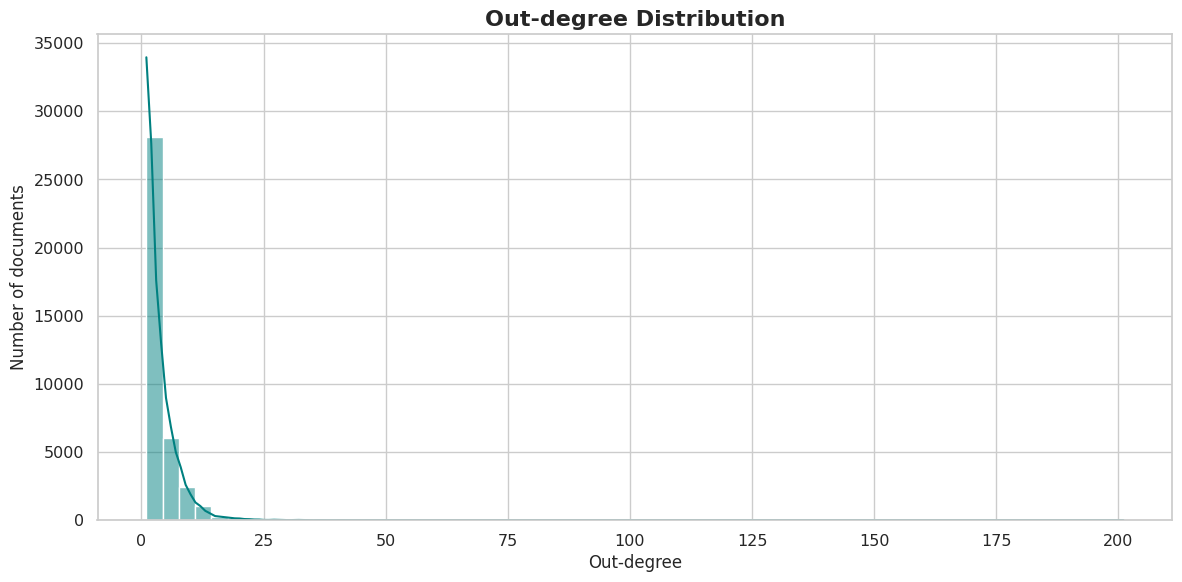

In [15]:
out_degree = (
    relationships
    .group_by("doc_id")
    .len()
    .rename({"len": "out_degree"})
)

out_degree_pd = out_degree.to_pandas()

plt.figure(figsize=(12, 6))
sns.histplot(
    data=out_degree_pd,
    x="out_degree",
    bins=60,
    kde=True,
    color="teal"
)

plt.title("Out-degree Distribution")
plt.xlabel("Out-degree")
plt.ylabel("Number of documents")
plt.tight_layout()
plt.show()

# 14. Top documents có nhiều relationships nhất

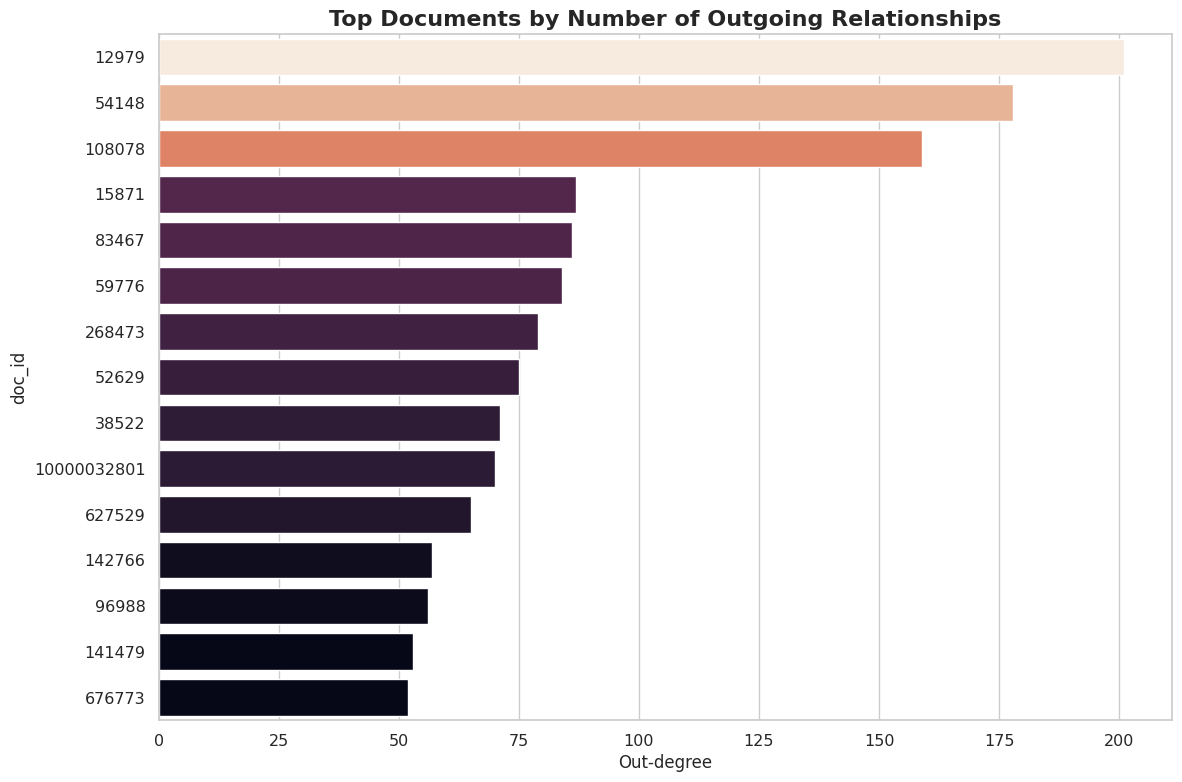

,doc_id,out_degree,title,legal_type,issuance_date
0,12979,201,Tiêu chuẩn và quy chuẩn kỹ thuật,Luật,2006-06-29
1,54148,178,Quy định chi tiết thi hành một số điều của Luậ...,Nghị định,2007-08-01
2,108078,159,Ngân hàng Nhà nước Việt Nam,Luật,2010-06-16
3,15871,87,Quản lý thuế,Luật,2006-11-29
4,83467,86,Quy định chi tiết thi hành một số điều của Luậ...,Nghị định,2008-12-31
5,59776,84,"Chất lượng sản phẩm, hàng hoá",Luật,2007-11-21
6,268473,79,"Ban hành Quy định về phân công, phân cấp và qu...",Quyết định,2014-12-16
7,52629,75,"Về chế độ tiền lương đối với cán bộ, công chức...",Nghị định,2004-12-14
8,38522,71,"Về nhiệm vụ, quyền hạn và trách nhiệm quản lý ...",Nghị định,1993-03-02
9,10000032801,70,Hiến pháp năm 2013,Hiến pháp,2013-11-28


In [16]:
top_degree = (
    out_degree
    .sort("out_degree", descending=True)
    .head(15)
    .join(
        metadata.select(["id", "title", "legal_type", "issuance_date"]),
        left_on="doc_id",
        right_on="id",
        how="left"
    )
    .to_pandas()
)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=top_degree,
    y=top_degree["doc_id"].astype(str),
    x="out_degree",
    hue="out_degree",
    palette="rocket",
    legend=False
)

plt.title("Top Documents by Number of Outgoing Relationships")
plt.xlabel("Out-degree")
plt.ylabel("doc_id")
plt.tight_layout()
plt.show()

display(top_degree)

# 16. Compact dashboard: 4 biểu đồ quan trọng nhất

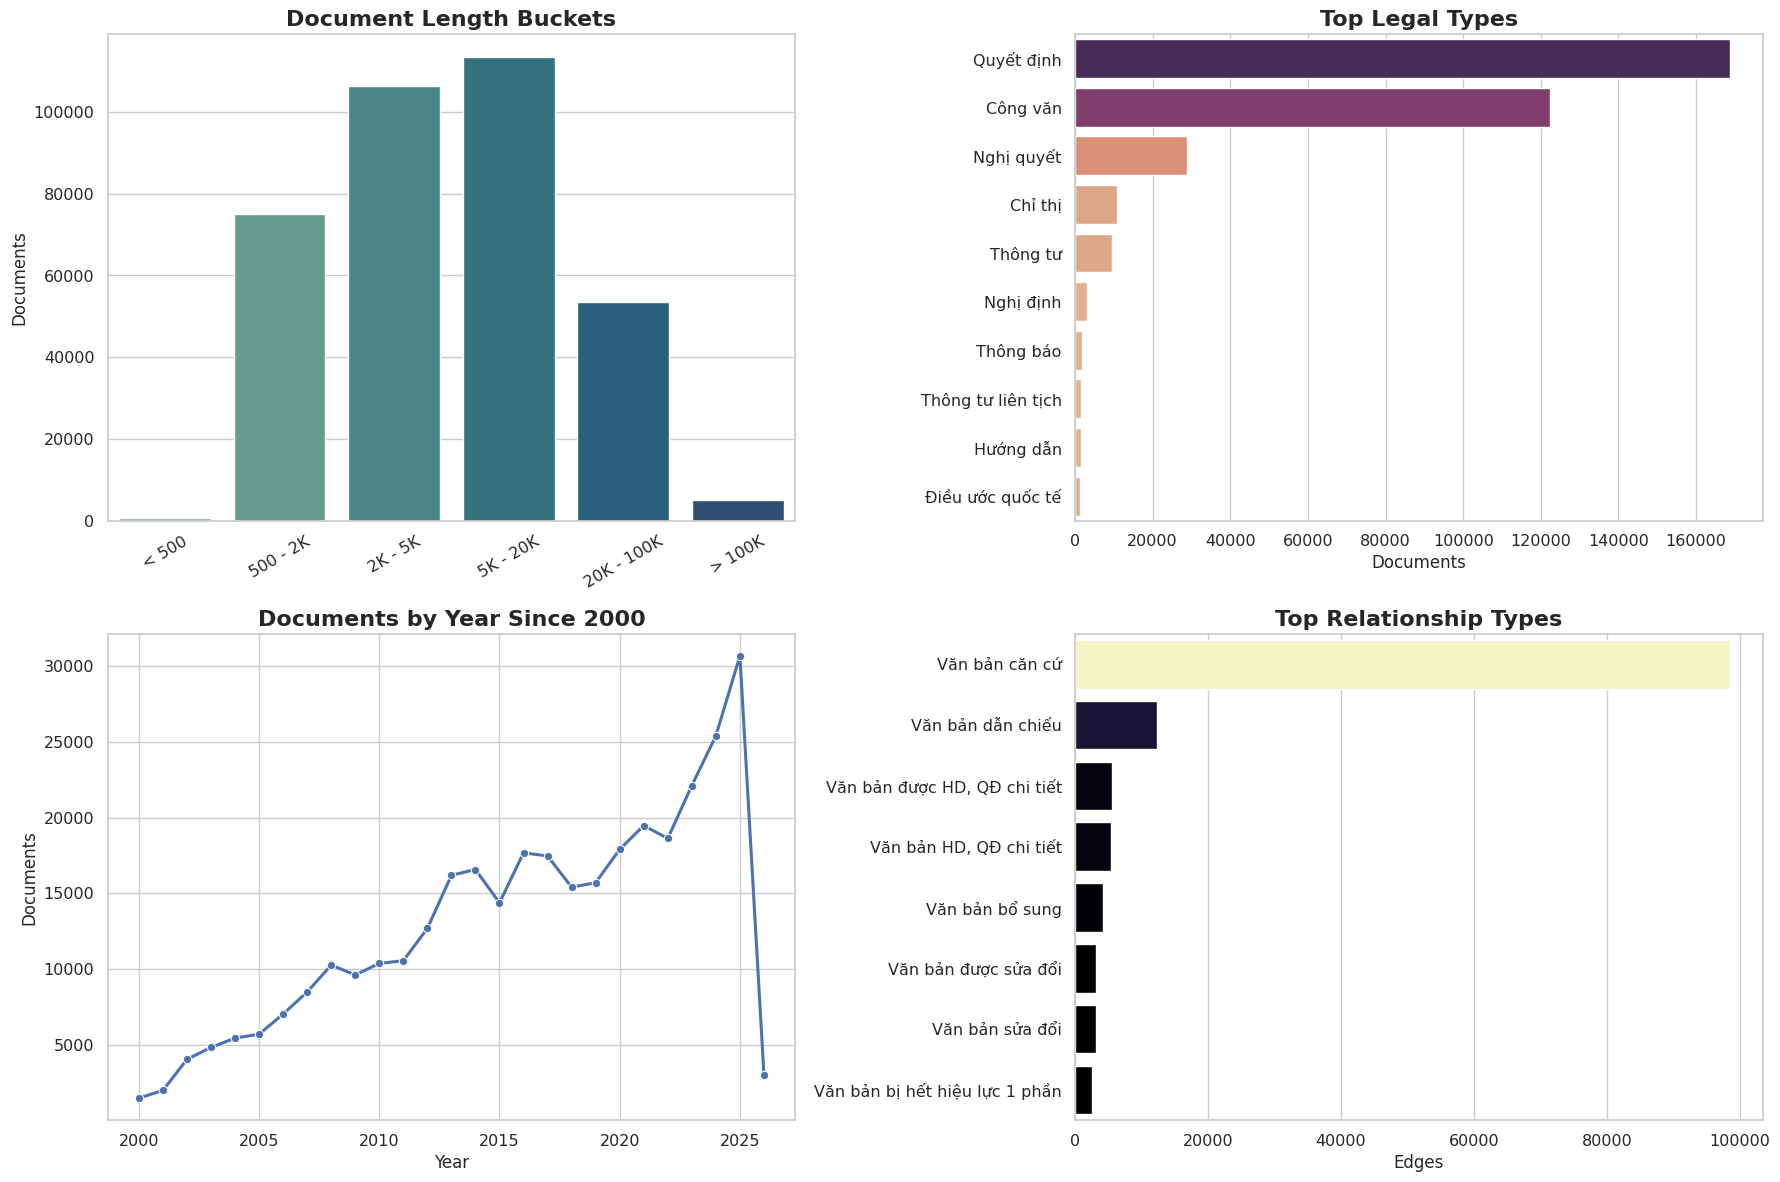

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

sns.barplot(
    data=bucket_pd,
    x="length_bucket",
    y="len",
    hue="length_bucket",
    palette="crest",
    legend=False,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Document Length Buckets")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Documents")
axes[0, 0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=top_legal_type.head(10),
    y="legal_type",
    x="len",
    hue="len",
    palette="flare",
    legend=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Top Legal Types")
axes[0, 1].set_xlabel("Documents")
axes[0, 1].set_ylabel("")

sns.lineplot(
    data=year_df[year_df["year"] >= 2000],
    x="year",
    y="len",
    marker="o",
    linewidth=2.2,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Documents by Year Since 2000")
axes[1, 0].set_xlabel("Year")
axes[1, 0].set_ylabel("Documents")

sns.barplot(
    data=rel_type_df.head(8),
    y="relationship",
    x="len",
    hue="len",
    palette="magma",
    legend=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Top Relationship Types")
axes[1, 1].set_xlabel("Edges")
axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.show()

# 17. Summarization

In [18]:
summary = {
    "n_documents": metadata.height,
    "n_content": content.height,
    "n_relationships": relationships.height,
    "n_unique_relationship_nodes": relationships.select(
        pl.concat_list(["doc_id", "other_doc_id"]).explode().n_unique()
    ).item(),
    "avg_content_len": round(content_len.select(pl.col("content_len").mean()).item(), 2),
    "median_content_len": round(content_len.select(pl.col("content_len").median()).item(), 2),
    "max_content_len": content_len.select(pl.col("content_len").max()).item(),
    "n_legal_types": metadata.select(pl.col("legal_type").n_unique()).item(),
    "n_issuing_authorities": metadata.select(pl.col("issuing_authority").n_unique()).item(),
}

summary

{'n_documents': 353746,
 'n_content': 353746,
 'n_relationships': 138656,
 'n_unique_relationship_nodes': 40604,
 'avg_content_len': 13030.25,
 'median_content_len': 4749.0,
 'max_content_len': 4585077,
 'n_legal_types': 38,
 'n_issuing_authorities': 1759}